## Assignment 06: Wi-Fi Protocol Performance


<div class="alert alert-light">

  **Name:** Suleman Ali Khan
  
  **Matriculation Number:** 21-715-917
  
</div>



The submission deadline is <span style="background-color:rgba(0, 150, 255, 0.5); padding:2px 4px; border-radius:3px;">Monday, 2026-Nov-02 (23:59)</span>.
Students <span style="background-color:rgba(255, 123, 0, 0.5); padding:2px 4px; border-radius:3px;">must work alone</span> and provide their own results. 

Fill in your responses below in the marked blocks. The expected length of each answer is provided in each block.

- (S) Short, 1–2 sentences (~20–40 words). *A quick factual or definition-style answer.*
- (M) Medium, 3–8 sentences (~60–120 words). *Brief explanation with reasoning or an example.*
- (L) Long, multi-paragraph (150–300 words). *Detailed discussion, include reasoning, examples, and context.*
- (V) Visualizations and graphs. *Include plots or figures that illustrate your results.*
- (E) Statistical evaluation and information. *Provide numeric context such as mean, variance, random seed used, confidence intervals, etc.*

Save this notebook and upload the modified file to Moodle.

The motivation for this assignment is to analyze the basics of the WLAN IEEE 802.11 medium access protocol in scenarios with many transmitting devices, instead of only one. When more than one station transmit data, radio resources are shared, and collisions might occur. The goal is to evaluate the performance of the underlying contention-based protocol: What is the maximum capacity, and what are the implications for the throughput with an increasing number of stations? Like before, as side-effect, emphasize is given on how to represent and visualize data, and how to derive conclusions from the evaluation.

---

## Questions



### Step 1: Multiple Transmitting Stations (3 points)

1) Open [`Jemula802_Run.ipynb`](../../notebooks/01%20Jemula/Jemula802_Run.ipynb). Input the scenario `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_WiFi_Multistation.xml"` and enter your legi number. How many stations are defined in this scenario? How many are transmitters?

<div class="alert alert-info">

(S) Answer: The scenario defines 37 stations in total, of which 36 are transmitters; the remaining station has no traffic generator and is the destination.

2.  Temporarily set `generateGoogleEarth="true"` and then run the scenario. It might be helpful to give the run more memory (e.g. `memory = "4G"` in the run cell of [`Jemula802_Run.ipynb`](../../notebooks/01%20Jemula/Jemula802_Run.ipynb)). Open [`Jemula802_Results.ipynb`](../../notebooks/01%20Jemula/Jemula802_Results.ipynb) and input the same scenario. Add a screenshot from Google Earth Pro of the scenario.

<div class="alert alert-info">

(V) Answer: 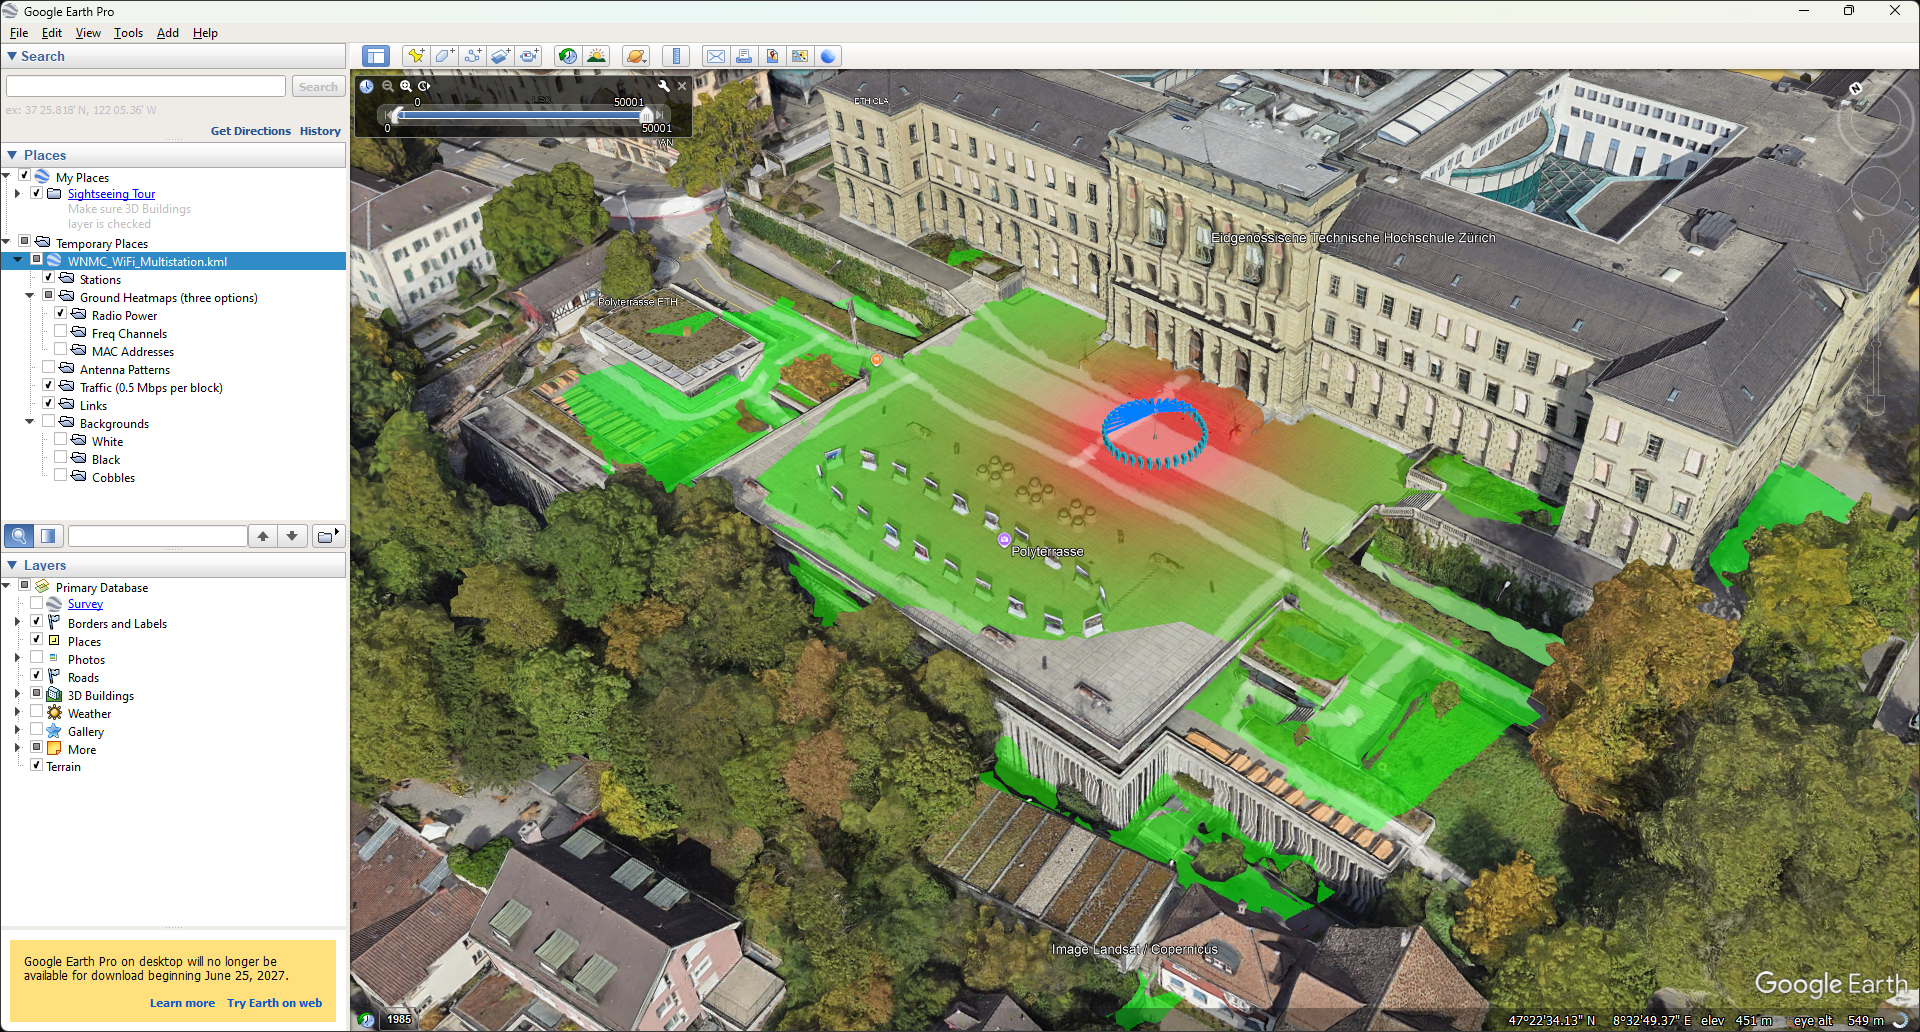

3.  Determine the saturation point by plotting throughput, offer and delay with the total logged outputs: at what time, and with how many active stations, does the throughput stop following the offer? Provide the graph. Then give the statistical confidence of total throughput and delay with [`Scientific_Confidence.ipynb`](../../notebooks/00%20Scientific/Scientific_Confidence.ipynb). The notebook uses all rows of a CSV, so adapt it to use only the values after the last station has started (from 38 s on).

<div class="alert alert-info">

(V, L, E) Answer:

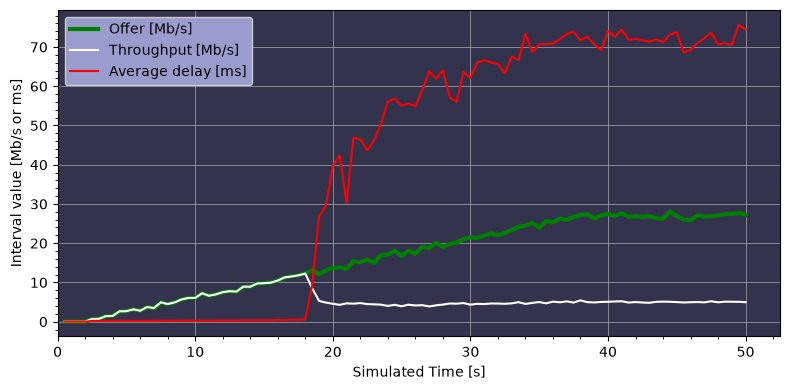

The plot shows that the offered traffic continues to increase as more stations begin transmitting, but the measured throughput stops increasing at around 18 s. This is the saturation point: the wireless network is no longer able to deliver the additional traffic being offered. At that time, 17 transmitting stations have started. The transmitters start one per second from 2 s onward, so the transmitters starting at 2–18 s are active by roughly 18 s. The scenario also includes a receiving station, which is not counted as a transmitter.

Dataset: total_thrp
 - Column:  thrp last interval [Mb/s]
 - n:       25
 - Mean:    5.02197 Mb/s
 - StdDev:  0.131821 Mb/s
 - SE:      0.0263642 Mb/s
 - 95% t CI: [4.96756, 5.07639] Mb/s

Dataset: total_delay
 - Column:  avrg last interval [ms]
 - n:       25
 - Mean:    71.9821 ms
 - StdDev:  1.74822 ms
 - SE:      0.349645 ms
 - 95% t CI: [71.2605, 72.7038] ms

4. What would happen with an increased number of stations beyond this saturation point? Explain why the throughput collapses and the value goes down.

<div class="alert alert-info">

(M) Answer: With more stations transmitting beyond the saturation point, the offered load keeps increasing, but the channel’s capacity does not. Stations must compete more often for access, causing additional backoff, collisions, and retransmissions. These consume airtime without successfully delivering new data, while packets wait longer in queues or may be dropped. As a result, the network spends a larger share of its time managing contention and recovering from failed transmissions. Eventually, successful data delivery can decrease, so the measured throughput falls even though more stations are sending traffic.

### Step 2: Modified MAC Parameters (3 points)
1) Open [`Jemula802_Run.ipynb`](../../notebooks/01%20Jemula/Jemula802_Run.ipynb) again and run each of the scenarios `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_WiFi_Multistation_AIFSN.xml"`, `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_WiFi_Multistation_CWMin.xml"`, and `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_WiFi_Multistation_Station10.xml"`. 

2. How has the AIFSN value been changed in `WNMC_WiFi_Multistation_AIFSN.xml` compared to the initial scenario and how does this change behavior?

<div class="alert alert-info">

(S) Answer: The AIFSN increases from 4 in the initial scenario to 8. Stations therefore wait longer before attempting to access the channel, increasing access delay and potentially reducing throughput.



3. How has the CWMin value been changed in `WNMC_WiFi_Multistation_CWMin.xml` compared to the initial scenario and how does this change behavior?

<div class="alert alert-info">

(S) Answer: CWMin increases from 5 in the initial scenario to 8. This enlarges the minimum backoff window, reducing the chance that stations transmit simultaneously, but makes them wait longer on average before transmitting.



4. How have the AIFSN and CWMin value been changed in `WNMC_WiFi_Multistation_Station10.xml` for Station 10 compared to the initial scenario? How does this change this stations behavior?

<div class="alert alert-info">

(S) Answer: In the initial scenario, Station 10 has AIFSN 4 and CWMin 5; in WNMC_WiFi_Multistation_Station10.xml, only Station 10 is changed to AIFSN 2 and CWMin 1. The shorter wait and backoff let it contend for the channel more aggressively than the other stations, potentially increasing its share of throughput while increasing contention for them.

5. Open [`Jemula802_Results.ipynb`](../../notebooks/01%20Jemula/Jemula802_Results.ipynb) and change the path to `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_WiFi_Multistation_AIFSN.xml"`. Illustrate the effects on total throughput and delay by providing the new plot, and interpret the changes.

<div class="alert alert-info">

(V, M) Answer: 

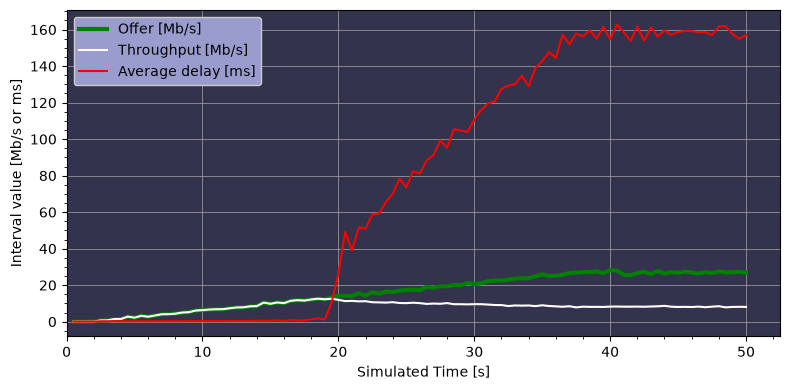

In the AIFSN scenario, the saturation point appears later than in the initial scenario: throughput continues to follow the offered load for longer before leveling off. This is consistent with the higher AIFSN (8 instead of 4), which makes stations wait longer before contending for the channel and can reduce simultaneous attempts. The trade-off is increased access delay.



6. Change the path to `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_WiFi_Multistation_CWMin.xml"`. Illustrate the effects on total throughput and delay by providing the new plot, and interpret the changes.

<div class="alert alert-info">

(V, M) Answer: 

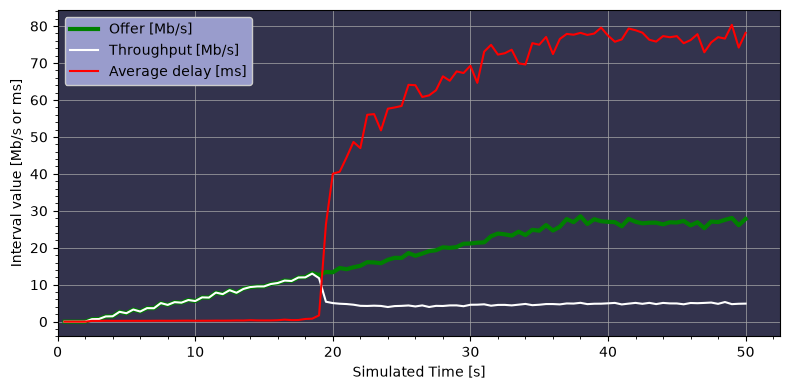

When compared to Base, CWMin increased from 5 to 8, stations choose a longer random backoff before transmitting. In the plot, throughput follows the offered load slightly longer, so saturation occurs later; however, throughput drops more sharply once saturation is reached. Delay is also slightly higher, consistent with stations waiting longer to access the channel. The change may reduce simultaneous transmission attempts, but the longer waits add contention overhead under heavy load.

7. Change the path to `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_WiFi_Multistation_Station10.xml"`, and use the logged data for station 10 (`thrp_file = "thrp_SA10_DA1_AC2_ID_140_data__End.csv"`, `offer_file = "offer_SA10_DA1_AC2_ID_140_data_.csv"`, `delay_file = "delay_SA10_DA1_AC2_ID_140_data__End.csv"`) . Provide the generated graph.

<div class="alert alert-info">

(V) Answer:

 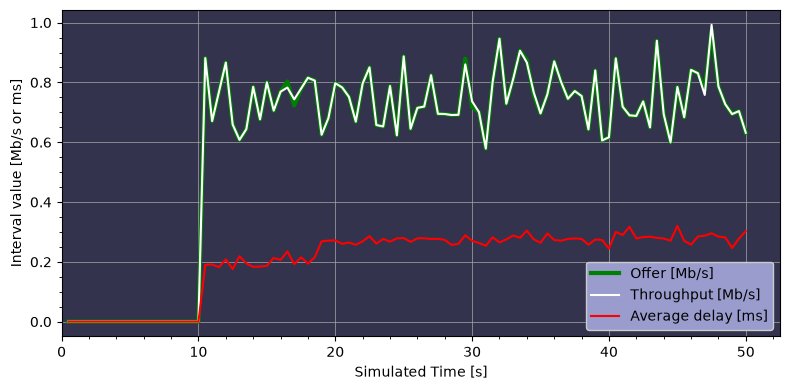

8. Also plot the logged data for the normal station 8 (`thrp_file = "thrp_SA8_DA1_AC2_ID_112_data__End.csv"`, `offer_file = "offer_SA8_DA1_AC2_ID_112_data_.csv"`, `delay_file = "delay_SA8_DA1_AC2_ID_112_data__End.csv"`) . Provide the generated graph.

<div class="alert alert-info">

(V) Answer:

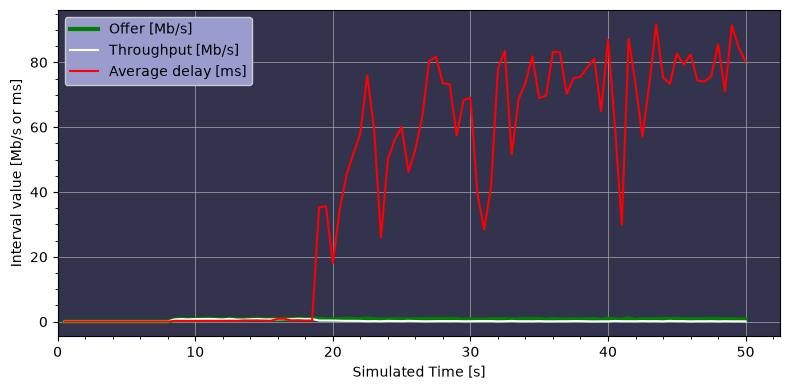

9. What happens if the parameters are changed for one station (station 10), but the rest remains the same? Analyze and interpret the differences in performance. Reference the graphs from above.

<div class="alert alert-info">

(M) Answer: The graphs show that changing only Station 10’s settings creates a highly unfair distribution of channel access. With its lower AIFSN and CWMin, Station 10 wins contention more often and captures almost all of its offered traffic, with delay around 0.2-0.3 ms. In contrast, Station 8 receives almost no throughput and its delay rises to nearly 100 ms, as it repeatedly waits for access while Station 10 transmits. Thus, the aggressive settings benefit Station 10 but severely degrade other stations’ performance.



### Step 3: Modified PHY Parameters (3 points)
1) Open [`Jemula802_Run.ipynb`](../../notebooks/01%20Jemula/Jemula802_Run.ipynb) again and run the scenario `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_WiFi_Multistation_PHY.xml"`. What has changed compared to the initial scenario?

<div class="alert alert-info">

(S) Answer: Station 10’s PHY mode is reduced from 54 Mbps to 6 Mbps. The scenario also increases CWMax from 10 to 100 for all stations, widening their backoff window and making them wait longer on average before transmitting.

2. Open [`Jemula802_Results.ipynb`](../../notebooks/01%20Jemula/Jemula802_Results.ipynb) and change the path to `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_WiFi_Multistation_PHY.xml"`. Provide the throughput, offer and delay plot separately for station 10 and station 8, using the same files as in Step 2 (questions 7 and 8). Interpret the changes compared to Step 2.

<div class="alert alert-info">

(V, M) Answer: 

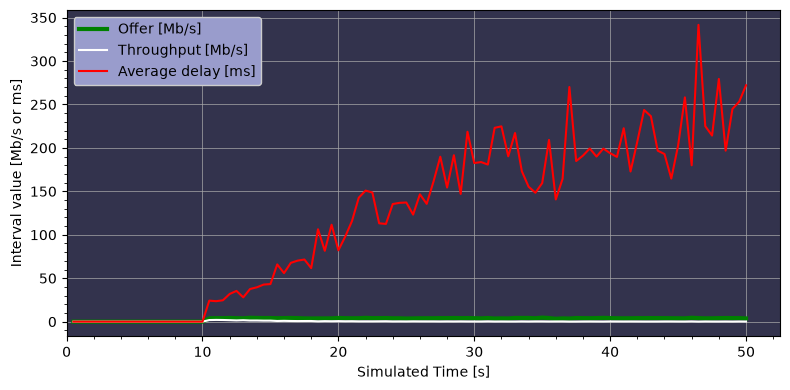

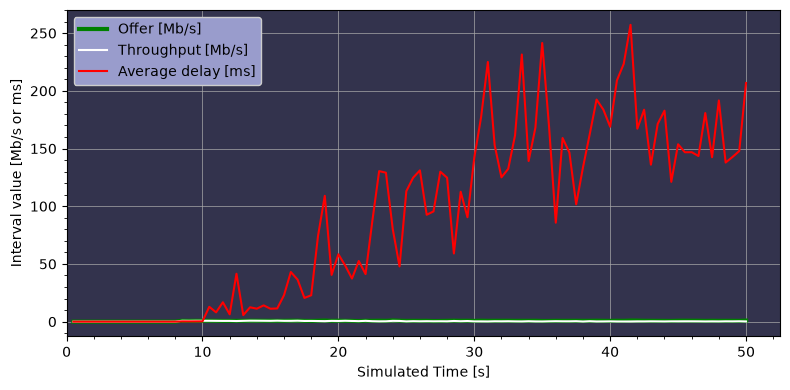

Compared with Step 2, the delay is much higher in the PHY scenario, rising from below 100 ms to over 250 ms, while throughput appears broadly similar. Station 10’s PHY rate is reduced from 54 Mbps to 6 Mbps, so its transmissions take longer and occupy the shared channel for more time. The PHY scenario also uses a larger CWMax, which can increase stations’ random backoff waits. Together, these changes can explain the higher delay without a major visible change in throughput. The plots still show that Station 10 receives most of the throughput, while Station 8 receives little.


3. What would happen if the transmission power of the stations (`dot11CurrentTransmitPowerLevel_dBm`) would change? Would there be any significant effects to be expected? Simulation results are not required.


<div class="alert alert-info">

(M) Answer: Changing transmit power changes how strongly a station’s signal is received. Higher power can improve reception at distant stations and reduce losses caused by weak signals, potentially increasing throughput. However, it also affects a larger area, so more stations may sense the transmission and defer, or interfere with one another; this can increase contention and reduce spatial reuse. Lower power may reduce interference but can make links unreliable or create hidden-terminal situations. Whether the effect is significant depends on station positions, channel conditions, and the simulator’s propagation model.


4) How would Station 10 be best configured in the following four settings to get its offered traffic through (to deliver all the data packets)? Simulation results are not required.
    - `dot11EDCAAIFSN`
    - `dot11EDCACWmin`
    - `PhyMode`
    - Transmission Power


<div class="alert alert-info">

(L) Answer: To give Station 10 the best chance of delivering all its offered traffic, I would configure it to gain channel access quickly and transmit efficiently. Set dot11EDCAAIFSN low (for example, 2, as in the Station 10 scenario) so it waits less after the channel becomes idle. Set dot11EDCACWmin low (for example, 1) so its random backoff is usually shorter. These settings make Station 10 more likely to transmit before competing stations, though they can make access less fair and increase other stations’ delays.

Choose the highest suitable PHY mode, such as 54 Mbps if the link supports it. A higher data rate sends each packet in less airtime, leaving more channel capacity for Station 10’s offered traffic. Set transmission power high enough for a reliable link, but not automatically to the maximum: extra power does not directly increase the data rate and may increase interference or contention for other stations.

These choices improve Station 10’s chances but cannot guarantee delivery of every packet. Success still depends on the total offered load, channel conditions, packet errors, and simulation duration; an overloaded network may not deliver all traffic even with aggressive settings.


### Optional Feedback (not graded)

1. Did you read through and understand all the tasks in this assignment and the related notebooks? Are there any shortcomings, missing parts, or sections that should be improved? You can also give your feedback anonymously, through moodle. Please help the teaching team by telling us what part was not understood, and we will work on it in the future.

<div class="alert alert-info">

Optional Feedback, not graded: *(double click to edit)*